In [1]:
# installing the libraries needed
!pip install pyLDAvis wordcloud -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.1 MB/s eta 0:00:00


In [1]:
import re, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

warnings.filterwarnings('ignore')
np.random.seed(42)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [2]:
url = "https://raw.githubusercontent.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing/master/Health_Related_Headlines_Dataset.csv"

try:
    df = pd.read_csv(url)
except UnicodeDecodeError:
    df = pd.read_csv(url, encoding='latin-1')

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (39405, 5)
Columns: ['Date', 'Source', 'Headlines', 'Teaser', 'Category']


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management


In [3]:
print(df.isnull().sum())
print()
print(df['Category'].value_counts())

Date         0
Source       0
Headlines    0
Teaser       0
Category     0
dtype: int64

Category
Clinical Trial                   9331
Pain Management                  9195
Substance Abuse and Addiction    6775
Patient Safety                   5911
Adverse Drug Event               4118
Immunization                     2729
Antibiotic Resistance            1346
Name: count, dtype: int64


In [4]:
# remove empty rows and duplicates
TEXT_COL = 'Headlines'

df = df.dropna(subset=[TEXT_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)
df = df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

# a sample keeps the later steps fast
if len(df) > 20000:
    df = df.sample(20000, random_state=42).reset_index(drop=True)

print("Documents:", len(df))

Documents: 20000


In [5]:
# lowercasing, punctuation removal, tokenization, stop-words, lemmatization
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                                   # lowercasing
    tokens = re.findall(r'[a-z]+', text)                  # tokenization + punctuation/number removal
    tokens = [w for w in tokens if w not in stop_words]   # stop-word removal
    tokens = [lemmatizer.lemmatize(w) for w in tokens]    # lemmatization
    tokens = [w for w in tokens if len(w) > 2]
    return tokens

df['tokens'] = df[TEXT_COL].apply(clean_text)
df = df[df['tokens'].str.len() > 0].reset_index(drop=True)
df['clean_text'] = df['tokens'].apply(lambda t: ' '.join(t))

print("Documents after cleaning:", len(df))
print()
for i in range(5):
    print("Original:", df[TEXT_COL][i])
    print("Cleaned :", df['clean_text'][i])
    print("-" * 50)

Documents after cleaning: 19999

Original: Hypereosinophilia Associated With Echinacea Use
Cleaned : hypereosinophilia associated echinacea use
--------------------------------------------------
Original: Mindfulness Therapy May Offer Alternative to Antidepressants
Cleaned : mindfulness therapy may offer alternative antidepressant
--------------------------------------------------
Original: Could a 'Default Option' Improve Cancer Care?
Cleaned : could default option improve cancer care
--------------------------------------------------
Original: Who Chooses Prepaid Dental Care?
Cleaned : chooses prepaid dental care
--------------------------------------------------
Original: Beer Is Less Harmful for the Liver than Plain Ethanol
Cleaned : beer less harmful liver plain ethanol
--------------------------------------------------


Total words: 115990 | Unique words: 12860


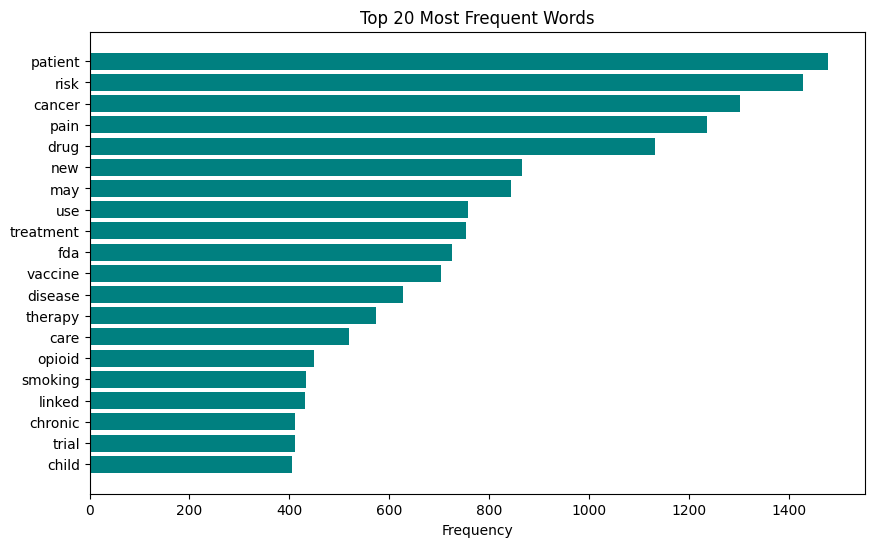

In [6]:
# word frequency and top 20 plot
all_words = [w for t in df['tokens'] for w in t]
word_freq = Counter(all_words)
print("Total words:", len(all_words), "| Unique words:", len(word_freq))

top20 = word_freq.most_common(20)
words = [w for w, c in top20][::-1]
counts = [c for w, c in top20][::-1]

plt.figure(figsize=(10, 6))
plt.barh(words, counts, color='teal')
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.show()

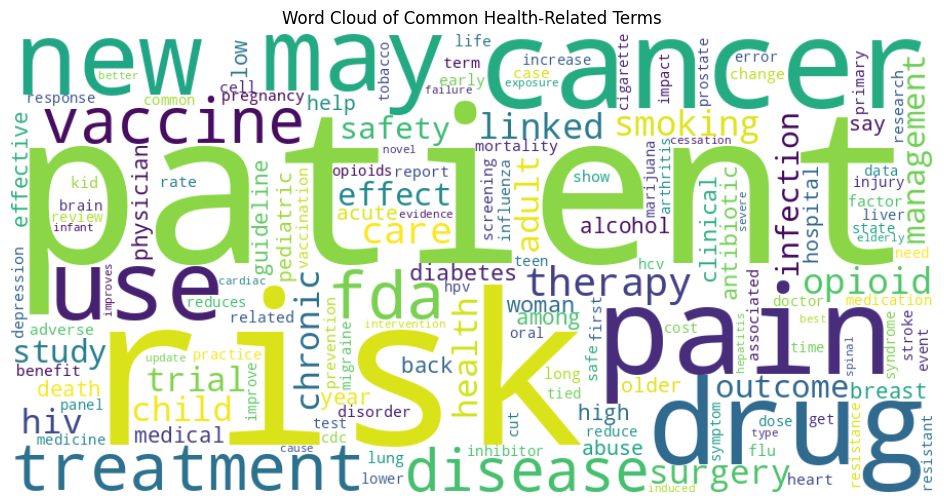

In [7]:
# word cloud
wc = WordCloud(width=900, height=450, background_color='white',
               max_words=150).generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Common Health-Related Terms")
plt.show()

In [8]:
# bag of words

vectorizer = CountVectorizer(max_df=0.9, min_df=5, max_features=5000)
dtm = vectorizer.fit_transform(df['clean_text'])

# remove documents that became empty after filtering
doc_lengths = np.asarray(dtm.sum(axis=1)).ravel()
keep = doc_lengths > 0
dtm = dtm[keep]
df = df[keep].reset_index(drop=True)

print("Document-term matrix:", dtm.shape)

Document-term matrix: (19947, 3466)


In [9]:
# Train LDA

NUM_TOPICS = 5

lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=42, max_iter=20)
lda.fit(dtm)
print("LDA trained")

LDA trained


In [10]:
# top 5 words per topic
feature_names = vectorizer.get_feature_names_out()

for idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-5:][::-1]]
    print(f"Topic {idx + 1}: {', '.join(top_words)}")

Topic 1: cancer, new, drug, trial, study
Topic 2: fda, disease, patient, treatment, risk
Topic 3: vaccine, surgery, risk, antibiotic, effect
Topic 4: risk, use, smoking, linked, adult
Topic 5: pain, patient, cancer, care, health


In [12]:
!pip install funcy numexpr -q
!pip install pyLDAvis --no-deps -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 50.6 MB/s eta 0:00:00


In [13]:
import pyLDAvis
print("pyLDAvis version:", pyLDAvis.__version__)

pyLDAvis version: 3.4.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
# pyLDAvis

import pyLDAvis
pyLDAvis.enable_notebook()

topic_term_dists = lda.components_ / lda.components_.sum(axis=1)[:, None]
doc_topic_dists = lda.transform(dtm)
doc_topic_dists = doc_topic_dists / doc_topic_dists.sum(axis=1)[:, None]
doc_lengths = np.asarray(dtm.sum(axis=1)).ravel()
term_frequency = np.asarray(dtm.sum(axis=0)).ravel()

vis = pyLDAvis.prepare(topic_term_dists, doc_topic_dists, doc_lengths,
                       feature_names, term_frequency, sort_topics=False)
vis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.224396 -0.111019       1        1  19.224942
1      0.004962  0.054042       2        1  20.323566
2     -0.118653  0.228601       3        1  17.901251
3     -0.254313 -0.192035       4        1  21.709237
4      0.143609  0.020410       5        1  20.841004, topic_info=           Term         Freq        Total Category  logprob  loglift
2220       pain  1191.000000  1191.000000  Default  30.0000  30.0000
452      cancer  1260.000000  1260.000000  Default  29.0000  29.0000
3328    vaccine   690.000000   690.000000  Default  28.0000  28.0000
2734       risk  1379.000000  1379.000000  Default  27.0000  27.0000
897     disease   605.000000   605.000000  Default  26.0000  26.0000
...         ...          ...          ...      ...      ...      ...
3148    therapy   127.837725   554.849277   Topic5  -5.1025   0.1003
3234  treatment   130.095928   728.493438   Topic5  -5.0850  -0.1545
1432   hospital    90.102324   211.669905   Topic5  -5.4523   0.7142
410      breast    86.416358   264.869268   Topic5  -5.4941   0.4482
2761     safety    86.522716   305.981999   Topic5  -5.4929   0.3051

[288 rows x 6 columns], token_table=      Topic      Freq      Term
term                           
18        2  0.204465     abuse
18        4  0.789332     abuse
36        2  0.975546      acid
52        3  0.985302  activity
54        2  0.597077     acute
...     ...       ...       ...
3452      1  0.518283      year
3452      2  0.180439      year
3452      3  0.245704      year
3452      4  0.057587      year
3459      4  0.992578     young

[369 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
